In [1]:
print("[BOOT] DrainBlock v2.8 FULL DATA started", flush=True)

[BOOT] DrainBlock v2.8 FULL DATA started


# 6% — DrainBlock Detector v2.8 — FULL DATA

Versi ini memakai **SEMUA image usable** dari dataset cleaned corpus.

Target berdasarkan audit sebelumnya:
- Metadata CSV: 25,000 rows
- Image usable di disk: 23,297
- Semua 23,297 image diproses CLIP
- Semua hasil pseudo-label dipakai dalam split train/val/test
- Tidak ada `CLIP_MAX_IMAGES=2500`
- Tidak ada `MAX_PER_CLASS=1200`
- Tidak ada balancing yang membuang data

Karena pseudo-label bisa imbalanced, training memakai **class-weighted CrossEntropyLoss** agar semua data tetap dipakai tanpa membuang kelas mayoritas.

> Penting: ini tetap weakly supervised general debris screening. Metric test mengukur agreement terhadap pseudo-label CLIP, bukan human-ground-truth drain blockage accuracy.

In [2]:
import os
import sys
import time
import json
import random
import shutil
import warnings
import gc
import subprocess
import importlib.util
from pathlib import Path

warnings.filterwarnings("ignore")

os.environ["PYTHONUNBUFFERED"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_XET"] = "1"

def log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)

print("[BOOT] heartbeat A", flush=True)
time.sleep(1)
print("[BOOT] heartbeat B", flush=True)

SEED = 42
random.seed(SEED)

DATA_ROOT = Path("/kaggle/input/datasets/loliwibu/global-trash-debris-cleaned-corpus")
IMAGE_DIR = DATA_ROOT / "images"
CSV_PATH = DATA_ROOT / "metadata.csv"

WORKDIR = Path("/kaggle/working/drainblock_full_v28")
REPORT_DIR = WORKDIR / "reports"
ASSET_DIR = WORKDIR / "assets"
MODEL_DIR = WORKDIR / "models"
OUTPUT_DIR = Path("/kaggle/working/drainblock_full_v28_output")

for p in [WORKDIR, REPORT_DIR, ASSET_DIR, MODEL_DIR, OUTPUT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# FULL DATA config
CLIP_BATCH_SIZE = 128
IMG_SIZE = 224
TRAIN_BATCH_SIZE = 64
STAGE1_EPOCHS = 2
STAGE2_EPOCHS = 2

log(f"[1/12] Python={sys.version.split()[0]}")
log(f"[1/12] DATA_ROOT={DATA_ROOT}")
log("[1/12] MODE=FULL DATA — no sampling, no balancing discard")

[BOOT] heartbeat A
[BOOT] heartbeat B
[11:59:06] [1/12] Python=3.13.15
[11:59:06] [1/12] DATA_ROOT=/kaggle/input/datasets/loliwibu/global-trash-debris-cleaned-corpus
[11:59:06] [1/12] MODE=FULL DATA — no sampling, no balancing discard


In [3]:
log("[2/12] Imports + GPU check started")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

log(f"[2/12] Torch={torch.__version__}")
log(f"[2/12] CUDA={torch.cuda.is_available()}")
log(f"[2/12] GPU count={torch.cuda.device_count()}")

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        log(f"[2/12] GPU {i}: {torch.cuda.get_device_name(i)}")

assert DATA_ROOT.exists(), f"Missing DATA_ROOT: {DATA_ROOT}"
assert IMAGE_DIR.exists(), f"Missing IMAGE_DIR: {IMAGE_DIR}"
assert CSV_PATH.exists(), f"Missing CSV_PATH: {CSV_PATH}"

log("[2/12] Dataset preflight OK")

[11:59:06] [2/12] Imports + GPU check started
[11:59:20] [2/12] Torch=2.11.0+cu128
[11:59:20] [2/12] CUDA=True
[11:59:20] [2/12] GPU count=2
[11:59:20] [2/12] GPU 0: Tesla T4
[11:59:20] [2/12] GPU 1: Tesla T4
[11:59:20] [2/12] Dataset preflight OK


In [4]:
log("[3/12] Transformers / CLIP check started")

if importlib.util.find_spec("transformers") is None:
    log("[3/12] transformers missing; installing")
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "transformers>=4.45.0,<5"
    ])

from transformers import CLIPModel, CLIPProcessor
import transformers

log(f"[3/12] transformers={transformers.__version__}")
log("[3/12] CLIP imports ready")

[11:59:20] [3/12] Transformers / CLIP check started
[11:59:32] [3/12] transformers=5.16.1
[11:59:32] [3/12] CLIP imports ready


In [5]:
log("[4/12] FULL dataset audit started")

df = pd.read_csv(CSV_PATH)

disk_images = sorted(IMAGE_DIR.glob("*.jpg"))
disk_names = {p.name for p in disk_images}
csv_names = set(df["filename"].astype(str))

usable = (
    df[df["filename"].isin(disk_names)]
    .copy()
    .reset_index(drop=True)
)

audit = {
    "csv_rows": int(len(df)),
    "csv_unique_filenames": int(len(csv_names)),
    "disk_images": int(len(disk_images)),
    "missing_images": int(len(csv_names - disk_names)),
    "extra_images": int(len(disk_names - csv_names)),
    "usable_rows": int(len(usable)),
    "full_data_mode": True,
}

print(json.dumps(audit, indent=2), flush=True)

(REPORT_DIR / "dataset_audit.json").write_text(
    json.dumps(audit, indent=2),
    encoding="utf-8"
)

assert len(usable) > 0

# Based on the known cleaned corpus audit.
if len(usable) != 23297:
    log(
        f"[4/12] WARNING expected 23297 usable rows from prior audit, "
        f"but current dataset has {len(usable)}. "
        f"Continuing with ALL currently usable rows."
    )

log(f"[4/12] ALL usable images selected={len(usable)}")
log("[4/12] FULL dataset audit complete")

[11:59:32] [4/12] FULL dataset audit started
{
  "csv_rows": 25000,
  "csv_unique_filenames": 25000,
  "disk_images": 23297,
  "missing_images": 1703,
  "extra_images": 0,
  "usable_rows": 23297,
  "full_data_mode": true
}
[11:59:32] [4/12] ALL usable images selected=23297
[11:59:32] [4/12] FULL dataset audit complete


In [6]:
log("[5/12] Preparing ALL images for CLIP pseudo-labeling")

# FULL DATA: no .sample(...)
clip_df = usable.copy().reset_index(drop=True)

cache_csv = REPORT_DIR / f"clip_weak_labels_FULL_{len(clip_df)}.csv"

log(f"[5/12] CLIP images={len(clip_df)}")
log(f"[5/12] CLIP batch size={CLIP_BATCH_SIZE}")
log(f"[5/12] Expected batches={(len(clip_df)+CLIP_BATCH_SIZE-1)//CLIP_BATCH_SIZE}")
log(f"[5/12] Cache={cache_csv}")

[11:59:32] [5/12] Preparing ALL images for CLIP pseudo-labeling
[11:59:32] [5/12] CLIP images=23297
[11:59:32] [5/12] CLIP batch size=128
[11:59:32] [5/12] Expected batches=183
[11:59:32] [5/12] Cache=/kaggle/working/drainblock_full_v28/reports/clip_weak_labels_FULL_23297.csv


In [7]:
log("[6/12] FULL CLIP pseudo-labeling started")

if cache_csv.exists():
    log(f"[6/12] Using existing FULL cache: {cache_csv}")
    pseudo_all = pd.read_csv(cache_csv)

else:
    CLIP_MODEL_NAME = "openai/clip-vit-base-patch32"

    log(f"[6/12] Loading CLIP model: {CLIP_MODEL_NAME}")
    t0 = time.time()

    clip_model = CLIPModel.from_pretrained(CLIP_MODEL_NAME).to(device)
    clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_NAME)
    clip_model.eval()

    log(f"[6/12] CLIP loaded in {time.time()-t0:.1f}s")

    prompts = [
        "a street or outdoor scene with visible trash, litter, garbage or debris on the ground",
        "a clean street, sidewalk or outdoor scene without visible trash or litter",
    ]

    # Robust CLIP text embedding for current Kaggle transformers builds.
    text_inputs = clip_processor(
        text=prompts,
        return_tensors="pt",
        padding=True
    )

    input_ids = text_inputs["input_ids"].to(device)
    attention_mask = text_inputs["attention_mask"].to(device)

    with torch.inference_mode():
        text_outputs = clip_model.text_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            return_dict=True
        )

        pooled_text = text_outputs.pooler_output
        text_features = clip_model.text_projection(pooled_text)
        text_features = text_features / text_features.norm(dim=-1, keepdim=True)

    log(f"[6/12] text_features shape={tuple(text_features.shape)}")

    records = []
    total_batches = (len(clip_df) + CLIP_BATCH_SIZE - 1) // CLIP_BATCH_SIZE
    started = time.time()

    log(f"[6/12] Processing ALL {len(clip_df)} images in {total_batches} batches")

    for batch_idx, start in enumerate(
        range(0, len(clip_df), CLIP_BATCH_SIZE),
        start=1
    ):
        batch_df = clip_df.iloc[start:start + CLIP_BATCH_SIZE]

        images = []
        valid_rows = []

        for _, row in batch_df.iterrows():
            image_path = IMAGE_DIR / row["filename"]

            try:
                with Image.open(image_path) as im:
                    images.append(im.convert("RGB"))
                valid_rows.append(row)
            except Exception as exc:
                log(
                    f"[6/12] skip unreadable {row['filename']}: "
                    f"{type(exc).__name__}"
                )

        if not images:
            log(f"[6/12] batch {batch_idx}/{total_batches} empty")
            continue

        processed = clip_processor(
            images=images,
            return_tensors="pt"
        )

        pixel_values = processed["pixel_values"].to(
            device,
            non_blocking=True
        )

        with torch.inference_mode():
            if torch.cuda.is_available():
                with torch.autocast(device_type="cuda", dtype=torch.float16):
                    vision_outputs = clip_model.vision_model(
                        pixel_values=pixel_values,
                        return_dict=True
                    )
                    pooled_image = vision_outputs.pooler_output
                    image_features = clip_model.visual_projection(pooled_image)
            else:
                vision_outputs = clip_model.vision_model(
                    pixel_values=pixel_values,
                    return_dict=True
                )
                pooled_image = vision_outputs.pooler_output
                image_features = clip_model.visual_projection(pooled_image)

            image_features = image_features / image_features.norm(
                dim=-1,
                keepdim=True
            )

            logits = (
                100.0
                * image_features.float()
                @ text_features.float().T
            )

            probs = logits.softmax(dim=-1).cpu().numpy()

        for row, prob in zip(valid_rows, probs):
            debris_prob = float(prob[0])
            clean_prob = float(prob[1])

            pred = (
                "debris"
                if debris_prob >= clean_prob
                else "clean_context"
            )

            records.append({
                "filename": row["filename"],
                "region": row.get("region", ""),
                "debris_clip_prob": debris_prob,
                "clean_clip_prob": clean_prob,
                "clip_pred": pred,
                "clip_confidence": max(debris_prob, clean_prob),
            })

        elapsed = time.time() - started
        rate = batch_idx / max(elapsed, 1e-6)
        eta = (total_batches - batch_idx) / max(rate, 1e-6)

        log(
            f"[6/12][CLIP] batch {batch_idx}/{total_batches} | "
            f"images_done={min(start+CLIP_BATCH_SIZE, len(clip_df))}/{len(clip_df)} | "
            f"elapsed={elapsed/60:.1f}m | ETA={eta/60:.1f}m"
        )

        del pixel_values, vision_outputs, pooled_image, image_features, logits
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    pseudo_all = pd.DataFrame(records)

    if len(pseudo_all) == 0:
        raise RuntimeError("CLIP generated zero pseudo labels.")

    pseudo_all.to_csv(cache_csv, index=False)

    del clip_model, clip_processor, text_outputs, pooled_text, text_features
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

log(f"[6/12] Pseudo labels generated={len(pseudo_all)} / usable={len(usable)}")

assert len(pseudo_all) == len(usable), (
    f"FULL DATA requirement failed: pseudo labels={len(pseudo_all)}, "
    f"usable={len(usable)}"
)

log("[6/12] Pseudo-label distribution:")
print(pseudo_all["clip_pred"].value_counts(), flush=True)

log("[6/12] Confidence summary:")
print(pseudo_all["clip_confidence"].describe(), flush=True)

log("[6/12] FULL CLIP pseudo-labeling complete")

[11:59:32] [6/12] FULL CLIP pseudo-labeling started
[11:59:32] [6/12] Loading CLIP model: openai/clip-vit-base-patch32


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

[11:59:42] [6/12] CLIP loaded in 9.9s
[11:59:43] [6/12] text_features shape=(2, 512)
[11:59:43] [6/12] Processing ALL 23297 images in 183 batches
[11:59:46] [6/12][CLIP] batch 1/183 | images_done=128/23297 | elapsed=0.0m | ETA=9.1m
[11:59:48] [6/12][CLIP] batch 2/183 | images_done=256/23297 | elapsed=0.1m | ETA=7.5m
[11:59:49] [6/12][CLIP] batch 3/183 | images_done=384/23297 | elapsed=0.1m | ETA=6.5m
[11:59:51] [6/12][CLIP] batch 4/183 | images_done=512/23297 | elapsed=0.1m | ETA=6.0m
[11:59:52] [6/12][CLIP] batch 5/183 | images_done=640/23297 | elapsed=0.2m | ETA=5.7m
[11:59:54] [6/12][CLIP] batch 6/183 | images_done=768/23297 | elapsed=0.2m | ETA=5.4m
[11:59:55] [6/12][CLIP] batch 7/183 | images_done=896/23297 | elapsed=0.2m | ETA=5.2m
[11:59:57] [6/12][CLIP] batch 8/183 | images_done=1024/23297 | elapsed=0.2m | ETA=5.1m
[11:59:58] [6/12][CLIP] batch 9/183 | images_done=1152/23297 | elapsed=0.3m | ETA=5.0m
[12:00:00] [6/12][CLIP] batch 10/183 | images_done=1280/23297 | elapsed=0.3m |

In [8]:
log("[7/12] Preparing ALL pseudo-labeled images — no filtering, no balancing discard")

# FULL DATA: every pseudo-labeled image is retained.
full_labeled = pseudo_all.copy().reset_index(drop=True)

full_labeled["label"] = (
    full_labeled["clip_pred"]
    .map({
        "clean_context": 0,
        "debris": 1,
    })
    .astype(int)
)

full_labeled.to_csv(
    REPORT_DIR / "full_pseudo_labels_ALL_IMAGES.csv",
    index=False
)

class_counts = full_labeled["label"].value_counts().sort_index()

log(f"[7/12] Class counts={class_counts.to_dict()}")
log(f"[7/12] Images retained={len(full_labeled)}")
log(f"[7/12] Images discarded=0")

assert len(full_labeled) == len(usable)

log("[7/12] ALL pseudo labels retained")

[12:04:14] [7/12] Preparing ALL pseudo-labeled images — no filtering, no balancing discard
[12:04:14] [7/12] Class counts={0: 5299, 1: 17998}
[12:04:14] [7/12] Images retained=23297
[12:04:14] [7/12] Images discarded=0
[12:04:14] [7/12] ALL pseudo labels retained


In [9]:
log("[8/12] Stratified split of ALL images started")

# 70% train, 15% validation, 15% pseudo-test.
train_df, temp_df = train_test_split(
    full_labeled,
    test_size=0.30,
    random_state=SEED,
    stratify=full_labeled["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

for name, frame in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df),
]:
    frame.to_csv(
        REPORT_DIR / f"{name}_FULL_pseudo.csv",
        index=False
    )

    log(
        f"[8/12] {name}={len(frame)} | "
        f"class_counts={frame['label'].value_counts().sort_index().to_dict()}"
    )

assert len(train_df) + len(val_df) + len(test_df) == len(full_labeled)

log("[8/12] ALL images accounted for in train/val/test")

[12:04:14] [8/12] Stratified split of ALL images started
[12:04:14] [8/12] train=16307 | class_counts={0: 3709, 1: 12598}
[12:04:14] [8/12] val=3495 | class_counts={0: 795, 1: 2700}
[12:04:14] [8/12] test=3495 | class_counts={0: 795, 1: 2700}
[12:04:14] [8/12] ALL images accounted for in train/val/test


In [10]:
log("[9/12] DataLoaders + class weights started")

train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    ),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    ),
])

class DebrisDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]

        with Image.open(IMAGE_DIR / row["filename"]) as im:
            image = im.convert("RGB")

        return self.transform(image), int(row["label"])

train_loader = DataLoader(
    DebrisDataset(train_df, train_tfms),
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    DebrisDataset(val_df, eval_tfms),
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    DebrisDataset(test_df, eval_tfms),
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Inverse-frequency class weights — keep all images, compensate imbalance.
train_counts = train_df["label"].value_counts().sort_index()

num_classes = 2
n_train = len(train_df)

weights_np = np.array([
    n_train / (num_classes * train_counts.get(i, 1))
    for i in range(num_classes)
], dtype=np.float32)

class_weights = torch.tensor(
    weights_np,
    dtype=torch.float32,
    device=device
)

log(f"[9/12] class_weights={class_weights.detach().cpu().tolist()}")
log(
    f"[9/12] train_batches={len(train_loader)} | "
    f"val_batches={len(val_loader)} | "
    f"test_batches={len(test_loader)}"
)

[12:04:14] [9/12] DataLoaders + class weights started
[12:04:14] [9/12] class_weights=[2.198301315307617, 0.6472058892250061]
[12:04:14] [9/12] train_batches=255 | val_batches=55 | test_batches=55


In [11]:
log("[10/12] MobileNetV3 setup started")

weights = MobileNet_V3_Small_Weights.DEFAULT
model = mobilenet_v3_small(weights=weights)

for p in model.features.parameters():
    p.requires_grad = False

model.classifier[-1] = nn.Linear(
    model.classifier[-1].in_features,
    2
)

model = model.to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

def evaluate(loader):
    model.eval()

    y_true = []
    y_pred = []
    total_loss = 0.0

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if torch.cuda.is_available():
                with torch.autocast(device_type="cuda", dtype=torch.float16):
                    logits = model(images)
                    loss = criterion(logits, labels)
            else:
                logits = model(images)
                loss = criterion(logits, labels)

            preds = logits.argmax(dim=1)

            total_loss += loss.item() * images.size(0)
            y_true.extend(labels.cpu().tolist())
            y_pred.extend(preds.cpu().tolist())

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1,
        "y_true": y_true,
        "y_pred": y_pred,
    }

def train_epoch(loader, optimizer, stage, epoch, total_epochs):
    model.train()
    total_loss = 0.0

    for batch_idx, (images, labels) in enumerate(loader, start=1):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        if torch.cuda.is_available():
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(images)
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * images.size(0)

        if batch_idx == 1 or batch_idx % 25 == 0 or batch_idx == len(loader):
            log(
                f"[10/12][{stage}] epoch={epoch}/{total_epochs} | "
                f"batch={batch_idx}/{len(loader)} | "
                f"loss={loss.item():.4f}"
            )

    return total_loss / len(loader.dataset)

log("[10/12] MobileNetV3 setup complete")

[12:04:14] [10/12] MobileNetV3 setup started
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 143MB/s]

[12:04:15] [10/12] MobileNetV3 setup complete


[12:04:15] [11/12] FULL DATA training started
[12:04:15] [11/12] Stage 1 epochs=2
[12:04:19] [10/12][stage1] epoch=1/2 | batch=1/255 | loss=0.6310
[12:04:23] [10/12][stage1] epoch=1/2 | batch=25/255 | loss=0.6049
[12:04:29] [10/12][stage1] epoch=1/2 | batch=50/255 | loss=0.5368
[12:04:34] [10/12][stage1] epoch=1/2 | batch=75/255 | loss=0.7156
[12:04:40] [10/12][stage1] epoch=1/2 | batch=100/255 | loss=0.6458
[12:04:46] [10/12][stage1] epoch=1/2 | batch=125/255 | loss=0.6537
[12:04:52] [10/12][stage1] epoch=1/2 | batch=150/255 | loss=0.5982
[12:04:57] [10/12][stage1] epoch=1/2 | batch=175/255 | loss=0.6629
[12:05:03] [10/12][stage1] epoch=1/2 | batch=200/255 | loss=0.5782
[12:05:09] [10/12][stage1] epoch=1/2 | batch=225/255 | loss=0.5325
[12:05:14] [10/12][stage1] epoch=1/2 | batch=250/255 | loss=0.5651
[12:05:17] [10/12][stage1] epoch=1/2 | batch=255/255 | loss=0.5497
[12:05:30] [11/12] stage1 epoch=1 | val_f1=0.6228 | val_acc=0.6718
[12:05:31] [10/12][stage1] epoch=2/2 | batch=1/255 |

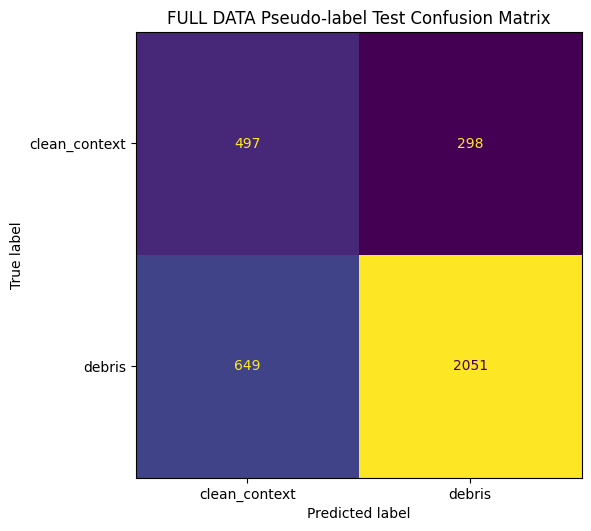

[12:09:18] [11/12] FULL DATA training + evaluation complete


In [12]:
log("[11/12] FULL DATA training started")

history = []
best_f1 = -1.0

best_path = MODEL_DIR / "mobilenetv3_full_weak_debris_best.pth"

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=3e-4,
    weight_decay=1e-4
)

log(f"[11/12] Stage 1 epochs={STAGE1_EPOCHS}")

for epoch in range(1, STAGE1_EPOCHS + 1):
    train_loss = train_epoch(
        train_loader,
        optimizer,
        "stage1",
        epoch,
        STAGE1_EPOCHS
    )

    metrics = evaluate(val_loader)

    history.append({
        "stage": 1,
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": metrics["loss"],
        "val_accuracy": metrics["accuracy"],
        "val_f1_macro": metrics["f1_macro"],
    })

    log(
        f"[11/12] stage1 epoch={epoch} | "
        f"val_f1={metrics['f1_macro']:.4f} | "
        f"val_acc={metrics['accuracy']:.4f}"
    )

    if metrics["f1_macro"] > best_f1:
        best_f1 = metrics["f1_macro"]
        torch.save(model.state_dict(), best_path)

model.load_state_dict(
    torch.load(best_path, map_location=device)
)

for block in list(model.features.children())[-2:]:
    for p in block.parameters():
        p.requires_grad = True

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=8e-5,
    weight_decay=1e-4
)

log(f"[11/12] Stage 2 epochs={STAGE2_EPOCHS}")

for epoch in range(1, STAGE2_EPOCHS + 1):
    train_loss = train_epoch(
        train_loader,
        optimizer,
        "stage2",
        epoch,
        STAGE2_EPOCHS
    )

    metrics = evaluate(val_loader)

    history.append({
        "stage": 2,
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": metrics["loss"],
        "val_accuracy": metrics["accuracy"],
        "val_f1_macro": metrics["f1_macro"],
    })

    log(
        f"[11/12] stage2 epoch={epoch} | "
        f"val_f1={metrics['f1_macro']:.4f} | "
        f"val_acc={metrics['accuracy']:.4f}"
    )

    if metrics["f1_macro"] > best_f1:
        best_f1 = metrics["f1_macro"]
        torch.save(model.state_dict(), best_path)

pd.DataFrame(history).to_csv(
    REPORT_DIR / "training_history_FULL_DATA.csv",
    index=False
)

model.load_state_dict(
    torch.load(best_path, map_location=device)
)

test_metrics = evaluate(test_loader)

print("Pseudo-test Accuracy:", f"{test_metrics['accuracy']:.4f}", flush=True)
print("Pseudo-test Macro Precision:", f"{test_metrics['precision_macro']:.4f}", flush=True)
print("Pseudo-test Macro Recall:", f"{test_metrics['recall_macro']:.4f}", flush=True)
print("Pseudo-test Macro F1:", f"{test_metrics['f1_macro']:.4f}", flush=True)

report = classification_report(
    test_metrics["y_true"],
    test_metrics["y_pred"],
    target_names=["clean_context", "debris"],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).T.to_csv(
    REPORT_DIR / "classification_report_FULL_pseudo_test.csv"
)

cm = confusion_matrix(
    test_metrics["y_true"],
    test_metrics["y_pred"]
)

fig, ax = plt.subplots(figsize=(6, 6))

ConfusionMatrixDisplay(
    cm,
    display_labels=["clean_context", "debris"]
).plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

plt.title("FULL DATA Pseudo-label Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    ASSET_DIR / "cm_FULL_pseudo_test.png",
    dpi=160
)

plt.show()

log("[11/12] FULL DATA training + evaluation complete")

In [13]:
log("[12/12] Saving compact FULL DATA artifacts")

final_model = OUTPUT_DIR / "drainblock_mobilenetv3_FULL_v28.pth"

checkpoint = {
    "model_state_dict": model.state_dict(),
    "class_names": ["clean_context", "debris"],
    "img_size": IMG_SIZE,
    "full_usable_images": int(len(usable)),
    "clip_images_processed": int(len(pseudo_all)),
    "all_images_retained": bool(len(full_labeled) == len(usable)),
    "class_weights": class_weights.detach().cpu().tolist(),
    "best_validation_f1": float(best_f1),
    "test_metrics": {
        "accuracy": float(test_metrics["accuracy"]),
        "precision_macro": float(test_metrics["precision_macro"]),
        "recall_macro": float(test_metrics["recall_macro"]),
        "f1_macro": float(test_metrics["f1_macro"]),
    }
}

torch.save(checkpoint, final_model)

# Copy reports/assets into output only. No dataset is packaged.
FINAL_REPORT_DIR = OUTPUT_DIR / "reports"
FINAL_ASSET_DIR = OUTPUT_DIR / "assets"

FINAL_REPORT_DIR.mkdir(parents=True, exist_ok=True)
FINAL_ASSET_DIR.mkdir(parents=True, exist_ok=True)

for f in REPORT_DIR.glob("*"):
    if f.is_file():
        shutil.copy2(f, FINAL_REPORT_DIR / f.name)

for f in ASSET_DIR.glob("*"):
    if f.is_file():
        shutil.copy2(f, FINAL_ASSET_DIR / f.name)

summary = {
    "project": "6% — DrainBlock Detector",
    "version": "v2.8 FULL DATA",
    "scope": "weakly supervised general debris screening baseline",
    "dataset_csv_rows": int(len(df)),
    "usable_images": int(len(usable)),
    "clip_images_processed": int(len(pseudo_all)),
    "images_retained_after_pseudo_labeling": int(len(full_labeled)),
    "images_discarded": int(len(usable) - len(full_labeled)),
    "train_size": int(len(train_df)),
    "val_size": int(len(val_df)),
    "test_size": int(len(test_df)),
    "stage1_epochs": STAGE1_EPOCHS,
    "stage2_epochs": STAGE2_EPOCHS,
    "best_val_macro_f1": float(best_f1),
    "pseudo_test_accuracy": float(test_metrics["accuracy"]),
    "pseudo_test_macro_precision": float(test_metrics["precision_macro"]),
    "pseudo_test_macro_recall": float(test_metrics["recall_macro"]),
    "pseudo_test_macro_f1": float(test_metrics["f1_macro"]),
    "all_usable_data_used": bool(
        len(pseudo_all) == len(usable)
        and len(full_labeled) == len(usable)
        and len(train_df) + len(val_df) + len(test_df) == len(usable)
    ),
    "warning": (
        "All usable corpus images are included, but labels are generated by CLIP. "
        "Metrics measure agreement with pseudo-labels, not human-ground-truth "
        "drain blockage accuracy. Source corpus is not drain-specific."
    )
}

(OUTPUT_DIR / "final_summary.json").write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8"
)

print(json.dumps(summary, indent=2), flush=True)

zip_path = shutil.make_archive(
    "/kaggle/working/drainblock_6pct_FULL_DATA_v28_outputs",
    "zip",
    root_dir=OUTPUT_DIR
)

log(f"[12/12] MODEL={final_model}")
log(f"[12/12] ZIP={zip_path}")
log("[DONE] DRAINBLOCK FULL DATA PIPELINE FINISHED")

[12:09:18] [12/12] Saving compact FULL DATA artifacts
{
  "project": "6% \u2014 DrainBlock Detector",
  "version": "v2.8 FULL DATA",
  "scope": "weakly supervised general debris screening baseline",
  "dataset_csv_rows": 25000,
  "usable_images": 23297,
  "clip_images_processed": 23297,
  "images_retained_after_pseudo_labeling": 23297,
  "images_discarded": 0,
  "train_size": 16307,
  "val_size": 3495,
  "test_size": 3495,
  "stage1_epochs": 2,
  "stage2_epochs": 2,
  "best_val_macro_f1": 0.6753489231392252,
  "pseudo_test_accuracy": 0.7290414878397711,
  "pseudo_test_macro_precision": 0.6534099393971814,
  "pseudo_test_macro_recall": 0.6923934311670161,
  "pseudo_test_macro_f1": 0.6622726339064189,
  "all_usable_data_used": true,
  "warning": "All usable corpus images are included, but labels are generated by CLIP. Metrics measure agreement with pseudo-labels, not human-ground-truth drain blockage accuracy. Source corpus is not drain-specific."
}
[12:09:19] [12/12] MODEL=/kaggle/worki